# QL18 corridor: study area and built-up share

The study area is the communes along **Quốc lộ 18**, from Bắc Ninh through Chí Linh
and Quảng Ninh to Móng Cái, not the whole delta. Steps:

1. Load every commune in Vietnam (GADM) and the OSM roads where QL18 runs.
2. Pick out QL18 and check the road read didn't cut it short.
3. Buffer it, choose the buffer distance, and keep the communes within it.
4. Clip the 10 m LULC raster to those communes and compute each one's built-up share.
5. Save the result as the AOI for `02_esda` and ribbon detection.

**Which road counts as QL18.** OSM signs two roads with QL18:
- **The old national road** (`tier == 'national'`, `ref` "QL.18"). Houses can front
  it, so this is where ribbons can grow. **It defines the corridor.**
- **Expressway sections co-signed QL18** (`ref` "CT.09;CT.38;QL.18", Nội Bài–Bắc
  Ninh). They are access-controlled, so no frontage is possible: context only.
  This is why the corridor starts at Bắc Ninh city rather than at Nội Bài.

In [1]:
from typing import Final

import geopandas as gpd
import pandas as pd

from desakota.crs import CRS_UTM
from desakota.highways import add_route_tier, compute_is_on_route, load_highways
from desakota.paths import DataLayout

TIME_RANGE: Final = '2023-01-02/2023-12-31'
BUILT_AREA_LABEL: Final = 'Built area'
WATER_LABEL: Final = 'Water'

ROUTE: Final = 'QL18'
CORRIDOR_BUFFER_M: Final = 2_000
# Where QL18 runs; roads are read only here (+2 km), section 2 checks that's enough.
SEED_PROVINCES: Final = ['BắcNinh', 'HảiDương', 'QuảngNinh']
SEED_DISTRICTS: Final = ['SócSơn']  # Nội Bài end, for the co-signed expressway context

layout = DataLayout.from_env().ensure()
GADM_PATH: Final = layout.raw / 'gadm41_VNM_3.json'  # GADM level 3 = communes
OSM_EXTRACT_PATH: Final = layout.raw / 'osm' / 'geofabrik_vietnam-261016' / 'vietnam.gpkg'
OUTPUT_STEM: Final = 'communes_ql18_corridor'

# GADM's GID_n / NAME_n, renamed once at load (README "Naming conventions").
GADM_COLUMNS: Final = {
    'GID_1': 'province_id',
    'NAME_1': 'province_name',
    'GID_2': 'district_id',
    'NAME_2': 'district_name',
    'GID_3': 'commune_id',
    'NAME_3': 'commune_name',
}

## 1. Communes and roads

All of Vietnam's communes are loaded, not just the seed provinces: a commune within
2 km of QL18 belongs in the corridor whatever province it is in (two are in Bắc
Giang). GADM ships EPSG:4326. Reprojecting the whole country into UTM 48N
distorts the far south-east, but only communes near QL18 (106–108°E, inside zone
48) are kept.

(11163, 603)

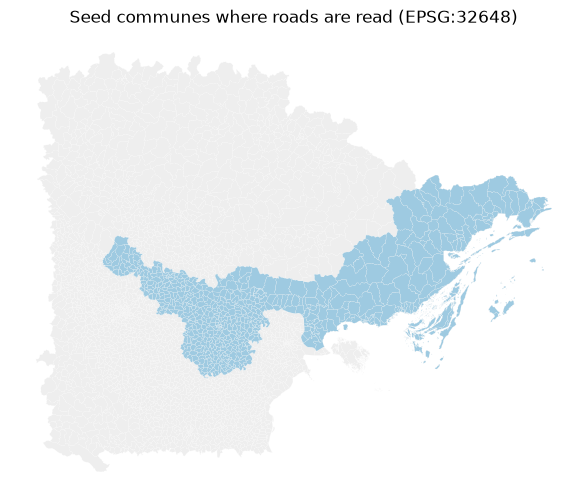

In [2]:
communes_wgs84 = gpd.read_file(GADM_PATH).rename(columns=GADM_COLUMNS)
communes = communes_wgs84[[*GADM_COLUMNS.values(), 'geometry']].to_crs(CRS_UTM)  # canonical

seed_communes = communes[
    communes['province_name'].isin(SEED_PROVINCES) | communes['district_name'].isin(SEED_DISTRICTS)
]
ax = communes.cx[550_000:850_000, 2_250_000:2_450_000].plot(
    color='#eeeeee', edgecolor='white', linewidth=0.1, figsize=(10, 6)
)
seed_communes.plot(ax=ax, color='#9ecae1', edgecolor='white', linewidth=0.1)
ax.set_title('Seed communes where roads are read (EPSG:32648)')
ax.set_axis_off()
len(communes), len(seed_communes)

Roads come from the Geofabrik Vietnam extract (OSM as of 2026-10-16, see
`raw/osm/geofabrik_vietnam-261016.json`). Reading takes a minute or two over 9P.

In [3]:
highways = add_route_tier(load_highways(OSM_EXTRACT_PATH, seed_communes))
highways['length_km'] = highways.length / 1000  # carriageway-km, see README caveats
len(highways)

3420

## 2. Pick out QL18

`compute_is_on_route` checks *every* route number on a way (`route` keeps only the
first, so "QL.17;QL.18" would be missed), then the tier splits the old road from
the expressway.

In [4]:
is_on_route = compute_is_on_route(highways, ROUTE)
route_ways = highways[is_on_route & (highways['tier'] == 'national')]
route_expressway_ways = highways[is_on_route & (highways['tier'] == 'expressway')]

highways[is_on_route].groupby(['tier', 'highway'])['length_km'].agg(['count', 'sum']).round(1)

count    sum
tier       highway               
expressway motorway    101   71.1
national   motorway      3    0.5
           primary     184   66.1
           trunk       622  329.6

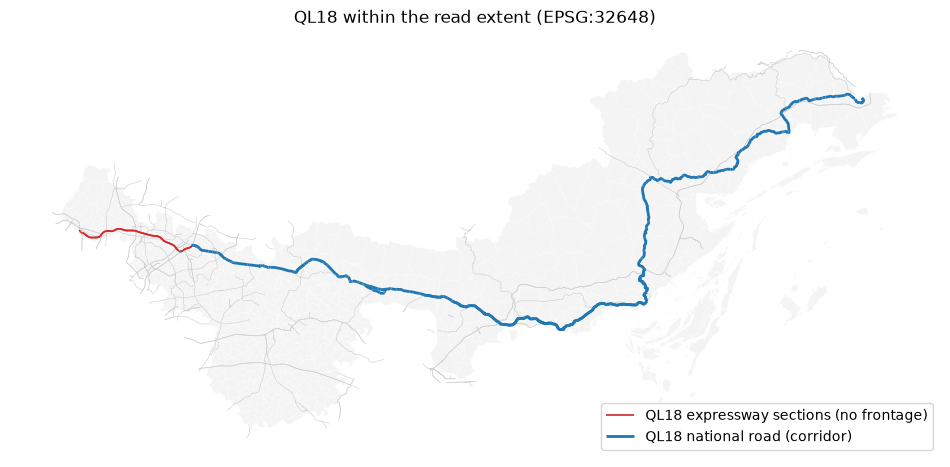

In [5]:
ax = seed_communes.plot(color='#f4f4f4', edgecolor='white', linewidth=0.2, figsize=(12, 6))
highways.plot(ax=ax, color='#cccccc', linewidth=0.4)
route_expressway_ways.plot(
    ax=ax, color='#d62728', linewidth=1.2, label='QL18 expressway sections (no frontage)'
)
route_ways.plot(ax=ax, color='#1f77b4', linewidth=2.0, label='QL18 national road (corridor)')
ax.legend(loc='lower right')
ax.set_title('QL18 within the read extent (EPSG:32648)')
ax.set_axis_off()

**Was QL18 cut off by the read extent?** `load_highways` reads the seed communes
plus a 2 km buffer. If the old road crosses the edge of that buffer, it continues
somewhere that wasn't read, and the seed should be widened. Expect no crossings.

In [6]:
# One MultiLineString; parallel one-way carriageways stay two lines.
route_line = route_ways.union_all()
read_extent = seed_communes.union_all().buffer(2_000)
crossings = route_line.intersection(read_extent.boundary)

print(f'QL18 old road: {route_line.length / 1000:.0f} km of centreline (divided: 2x)')
print(
    'crossings of the read-extent edge (possible truncation):',
    0 if crossings.is_empty else len(getattr(crossings, 'geoms', [crossings])),
)

QL18 old road: 396 km of centreline (divided: 2x)
crossings of the read-extent edge (possible truncation): 0


## 3. Corridor: how wide?

A commune joins the AOI if it lies within `CORRIDOR_BUFFER_M` of the old road. The
table shows how the AOI grows with the buffer. Keep three scales in mind:
- **Ribbons:** about 25–100 m from the road edge.
- **Commune:** about 2.4 km across (median in the delta).
- **Comparison:** testing whether ribbon density falls off with distance needs
  communes well away from the road, not only the ones it crosses.

In [7]:
nearby_communes = communes[communes.dwithin(route_line, 5_000)]  # cheap prefilter, vectorised GEOS
route_dist_m = nearby_communes.distance(route_line)  # 0 for communes QL18 passes through

pd.DataFrame(
    [
        {
            'corridor_buffer_m': buffer_m,
            'n_communes': int((route_dist_m <= buffer_m).sum()),
            'area_km2': round(nearby_communes.loc[route_dist_m <= buffer_m].area.sum() / 1e6),
        }
        for buffer_m in (0, 500, 1_000, 2_000, 3_000, 5_000)
    ]
)

,corridor_buffer_m,n_communes,area_km2
0,0,97,1719
1,500,112,2028
2,1000,136,2395
3,2000,171,3281
4,3000,195,3714
5,5000,243,4655


In [8]:
is_in_corridor = route_dist_m <= CORRIDOR_BUFFER_M
corridor = route_line.buffer(CORRIDOR_BUFFER_M)
corridor_communes = (
    nearby_communes[is_in_corridor]
    .assign(
        dist_to_ql18_m=route_dist_m[is_in_corridor].round(1),
        is_crossed_by_ql18=lambda frame: frame['dist_to_ql18_m'] == 0,
    )
    .reset_index(drop=True)
)
print(corridor_communes.groupby('province_name').size().to_string())
corridor_communes['is_crossed_by_ql18'].value_counts()

province_name
BắcGiang       2
BắcNinh       37
HảiDương      14
QuảngNinh    118


is_crossed_by_ql18
True     97
False    74
Name: count, dtype: int64

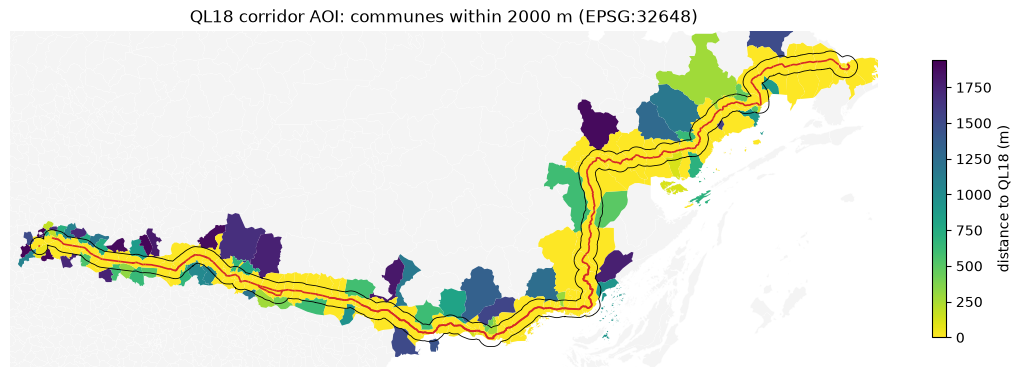

In [9]:
ax = communes.cx[550_000:850_000, 2_250_000:2_450_000].plot(
    color='#f4f4f4', edgecolor='white', linewidth=0.2, figsize=(14, 6)
)
corridor_communes.plot(
    ax=ax,
    column='dist_to_ql18_m',
    cmap='viridis_r',
    legend=True,
    legend_kwds={'label': 'distance to QL18 (m)', 'shrink': 0.6},
)
gpd.GeoSeries([corridor], crs=CRS_UTM).boundary.plot(ax=ax, color='black', linewidth=0.6)
route_ways.plot(ax=ax, color='#d62728', linewidth=1.2)
minx, miny, maxx, maxy = corridor.bounds
ax.set_xlim(minx - 5_000, maxx + 5_000)
ax.set_ylim(miny - 5_000, maxy + 5_000)
ax.set_title(f'QL18 corridor AOI: communes within {CORRIDOR_BUFFER_M} m (EPSG:32648)')
ax.set_axis_off()

Interactive version: hover to find a commune, for example your own.

In [10]:
corridor_communes.explore(
    column='dist_to_ql18_m',
    cmap='viridis_r',
    tooltip=['province_name', 'district_name', 'commune_name', 'dist_to_ql18_m'],
)

## 4. Land cover for the corridor

**Which tile.** Each LULC item is a UTM-zone × latitude-band mosaic. The corridor's
east end (Móng Cái, 108.05°E) is just past zone 48's nominal edge (108°E), so the
search returns both 48Q and 49Q. Their footprints overlap, though, and 48Q's reaches
108.16°E, so 48Q alone covers the corridor in the working CRS (EPSG:32648). Pick it
explicitly rather than taking whichever comes first.

In [11]:
from desakota.stac import create_client, get_bbox_from_aoi, get_collection, search_items

client = create_client()
collection = get_collection(client, '10M_ANNUAL_LANDUSE')

bbox_wgs84 = get_bbox_from_aoi(
    corridor_communes.to_crs(communes_wgs84.crs)
)  # STAC wants EPSG:4326 lon/lat
items = list(search_items(client, collection, bbox=bbox_wgs84, datetime=TIME_RANGE).items())
print([item.id for item in items])

zone_48_items = [item for item in items if item.id.startswith('48Q')]
assert len(zone_48_items) == 1, [item.id for item in items]
lulc_item = zone_48_items[0]
lulc_item.id

['49Q-2023', '48Q-2023']


'48Q-2023'

In [12]:
from desakota.landcover import fetch_landcover

# Windowed read of only the corridor's bounding box from the remote COG, cached under
# raw/lulc with a JSON sidecar (item id, unsigned href, window). Reuses the file on rerun.
# fetch_landcover raises if the corridor extends past the tile, rather than clipping.
lulc_path = fetch_landcover(corridor_communes, lulc_item, cache_dir=layout.raw / 'lulc')
lulc_path

PosixPath('/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/data/raw/lulc/lulc_48Q-2023_3d7e0d2660ca.tif')

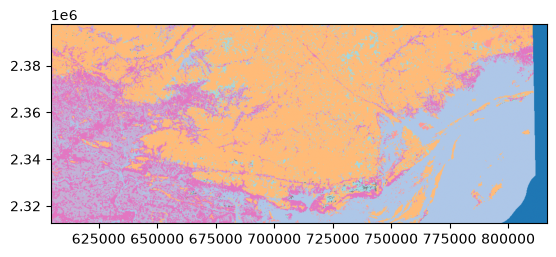

<Axes: >

In [13]:
import rasterio
from rasterio.plot import show

PREVIEW_STEP_PX = 20  # 200 m preview; default nearest-neighbour keeps class values intact

with rasterio.open(lulc_path) as lulc_src:
    assert lulc_src.crs == corridor_communes.crs  # vector-meets-raster boundary
    preview = lulc_src.read(
        1, out_shape=(lulc_src.height // PREVIEW_STEP_PX, lulc_src.width // PREVIEW_STEP_PX)
    )
    preview_transform = lulc_src.transform * lulc_src.transform.scale(
        lulc_src.width / preview.shape[1], lulc_src.height / preview.shape[0]
    )

ax = show(preview, transform=preview_transform, cmap='tab20')
corridor_communes.boundary.plot(ax=ax, color='black', linewidth=0.2)

## 5. Built-up share per commune

Share of non-water pixels classed Built area. No-data pixels (0) are excluded, so
any unmapped strip at the tile edge does not bias it.

In [14]:
from desakota.landcover import compute_built_frac, get_landcover_legend

legend = get_landcover_legend(collection)

corridor_communes['built_frac'] = compute_built_frac(
    aoi=corridor_communes,
    raster_path=lulc_path,
    legend=legend,
    built_area_label=BUILT_AREA_LABEL,
    water_label=WATER_LABEL,
)
corridor_communes['built_frac'].describe()

count    171.000000
mean       0.450357
std        0.263493
min        0.017128
25%        0.250785
50%        0.407721
75%        0.606095
max        1.000000
Name: built_frac, dtype: float64

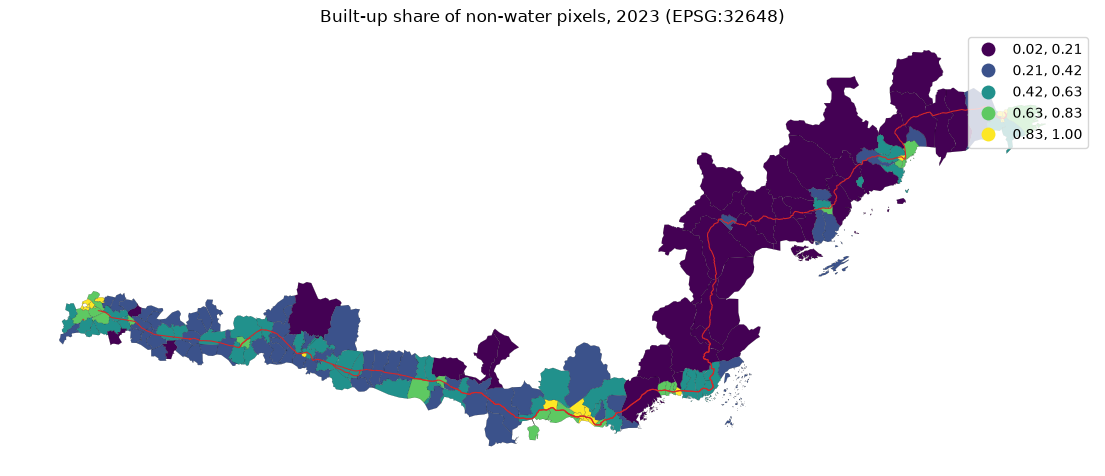

In [15]:
ax = corridor_communes.plot(
    column='built_frac',
    legend=True,
    edgecolor='black',
    linewidth=0.1,
    scheme='FisherJenks',
    figsize=(14, 6),
)
route_ways.plot(ax=ax, color='#d62728', linewidth=0.8)
ax.set_title('Built-up share of non-water pixels, 2023 (EPSG:32648)')
ax.set_axis_off()

## 6. Save the AOI and the route

The QL18 ways are saved too, so later notebooks can rebuild the corridor without
re-reading the 1.4 GB extract.

In [16]:
corridor_communes.to_file(
    layout.processed / f'{OUTPUT_STEM}.gpkg', layer=OUTPUT_STEM, driver='GPKG'
)
route_stem = 'highways_ql18'  # national-tier QL18 ways only, EPSG:32648
route_ways.to_file(layout.processed / f'{route_stem}.gpkg', layer=route_stem, driver='GPKG')
OUTPUT_STEM, len(corridor_communes), route_stem, len(route_ways)

('communes_ql18_corridor', 171, 'highways_ql18', 809)